# 08 — Clustering Experiment: Small Latent Space
Explores how a very compressed latent temporal dimension `(1, T)` affects cluster quality.
Key knob: `LATENT_T` — set to 10 for monthly-resolution, 52 for weekly, 182 for the default.

In [10]:
## 1. Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
from dtaidistance import dtw
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from dotenv import load_dotenv
from divvy_demand.infra.s3_client import S3Client

load_dotenv("../../.env")
s3 = S3Client(env="prod")
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}")


Device: mps


In [11]:
## 2. Data prep
station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])

# Use 2023 — full year, dense signal
df = station[station['date'].dt.year == 2023].copy()
pivot = df.pivot_table(index='start_station_name', columns='date', values='total_rides', fill_value=0)

# Same filter as notebook 05: stations active on >= 7 days
MIN_ACTIVE_DAYS = 7
pivot = pivot[(pivot > 0).sum(axis=1) >= MIN_ACTIVE_DAYS]
print(f'Stations kept (>= {MIN_ACTIVE_DAYS} active days): {len(pivot)}')

# Normalise per-station to [0, 1]
rides_scaled = MinMaxScaler().fit_transform(pivot.T).T
X = rides_scaled[:, None, :]  # (n_stations, 1, n_days)

n_stations, _, n_days = X.shape
print(f'X shape: {X.shape}  — (stations, 1, days)')

# Train / val split — same seed and ratio as notebook 05
np.random.seed(42)
idx = np.random.permutation(n_stations)
split = int(0.8 * n_stations)
train_idx, val_idx = idx[:split], idx[split:]

X_tensor = torch.tensor(X, dtype=torch.float32)
X_train  = X_tensor[train_idx]
X_val    = X_tensor[val_idx]

train_loader = DataLoader(TensorDataset(X_train), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val),   batch_size=64, shuffle=False)
print(f'Train: {len(X_train)} stations | Val: {len(X_val)} stations')


Stations kept (>= 7 active days): 1301
X shape: (1301, 1, 365)  — (stations, 1, days)
Train: 1040 stations | Val: 261 stations


In [12]:
## 3. Model — global avg pool latent + learnable temporal template in decoder
import torch.nn.functional as F

# ── KEY KNOB ──────────────────────────────────────────────
LATENT_T = 10    # number of channel summaries in the flat latent vector
# ──────────────────────────────────────────────────────────

N_FEATURES = 1
SEQ_LEN    = n_days  # 365

class InceptionBlock1D(nn.Module):
    KERNELS = [2, 3, 4, 5,6, 7, 14, 21, 30, 60, 91]
    def __init__(self, in_channels, out_per_branch):
        super().__init__()
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(in_channels, out_per_branch, kernel_size=k, padding=k // 2),
                nn.BatchNorm1d(out_per_branch), nn.ReLU(),
            ) for k in self.KERNELS
        ])
        out_channels = out_per_branch * len(self.KERNELS)
        self.residual_proj = nn.Conv1d(in_channels, out_channels, kernel_size=1)
    def forward(self, x):
        outs = [b(x) for b in self.branches]
        min_len = min(o.shape[-1] for o in outs)
        out = torch.cat([o[..., :min_len] for o in outs], dim=1)
        return out + self.residual_proj(x)[..., :min_len]

class CNNAutoencoder(nn.Module):
    def __init__(self, n_features, seq_len, latent_dim):
        super().__init__()
        self.seq_len   = seq_len
        self.latent_dim = latent_dim
        enc1_out = 8 * len(InceptionBlock1D.KERNELS)  # 64

        # Encoder
        self.enc1 = InceptionBlock1D(n_features, 8)   # (1,  365) → (64, 365)
        self.mix  = nn.Sequential(                     # (64, 365) → (latent_dim, 365)
            nn.Conv1d(enc1_out, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16), nn.ReLU(),
            nn.Conv1d(16, latent_dim, kernel_size=7, padding=3),
            nn.BatchNorm1d(latent_dim), nn.ReLU(),
        )
        # Global avg pool → flat latent: (latent_dim, 365) → (latent_dim,)
        self.gap = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
        )

        # Learnable temporal template shared across all stations
        self.time_embed = nn.Parameter(torch.randn(1, 1, seq_len) * 0.01)

        # Decoder: z broadcast across time + positional signal → reconstruction
        self.dec_input = nn.Conv1d(latent_dim + 1, 16, kernel_size=1)
        self.demix = nn.Sequential(
            nn.Conv1d(16, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, enc1_out, kernel_size=7, padding=3),
            nn.BatchNorm1d(enc1_out), nn.ReLU(),
        )
        self.out_proj = nn.Conv1d(enc1_out, n_features, kernel_size=3, padding=1)

    def encode(self, x):
        # (batch, 1, 365) → (batch, latent_dim)
        return self.gap(self.mix(self.enc1(x)))

    def decode(self, z):
        batch = z.shape[0]
        z_exp = z.unsqueeze(-1).expand(-1, -1, self.seq_len)      # (B, latent_dim, 365)
        pos   = self.time_embed.expand(batch, -1, -1)              # (B, 1, 365)
        h = torch.cat([z_exp, pos], dim=1)                         # (B, latent_dim+1, 365)
        h = self.dec_input(h)
        h = self.demix(h)
        return torch.sigmoid(self.out_proj(h))

    def forward(self, x):
        return self.decode(self.encode(x))

model = CNNAutoencoder(N_FEATURES, SEQ_LEN, latent_dim=LATENT_T).to(device)
with torch.no_grad():
    dummy = torch.zeros(2, N_FEATURES, SEQ_LEN).to(device)
    z   = model.encode(dummy)
    out = model.decode(z)
    print(f"Input:  {tuple(dummy.shape)}")
    print(f"Latent: {tuple(z.shape)}  — flat, no temporal order")
    ok = "OK" if out.shape == dummy.shape else "MISMATCH"
    print(f"Output: {tuple(out.shape)}  {ok}")
    print(f"Params: {sum(p.numel() for p in model.parameters()):,}")


Input:  (2, 1, 365)
Latent: (2, 10)  — flat, no temporal order
Output: (2, 1, 365)  OK
Params: 51,452


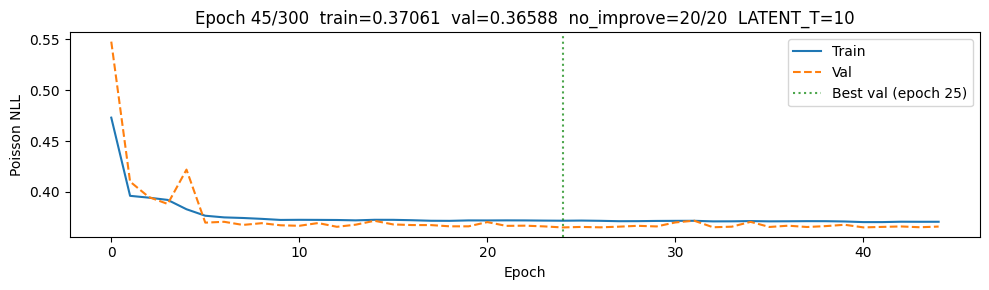

Early stopping at epoch 45 — no val improvement for 20 epochs
Restored best model  val=0.365042


In [13]:
## 4. Training (live loss plot)
from IPython.display import clear_output

EPOCHS, LR, PATIENCE, MIN_DELTA = 300, 1e-3, 20, 1e-6
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
# Poisson NLL: pred - target*log(pred)  — suited for count-like data
# log_input=False because decoder outputs Sigmoid (already non-negative rates)
criterion = nn.PoissonNLLLoss(log_input=False, full=False, reduction="mean")
train_losses, val_losses = [], []
best_val, best_state, no_improve = float('inf'), None, 0

for epoch in range(1, EPOCHS + 1):
    # --- train ---
    model.train()
    t_loss = 0
    for (batch,) in train_loader:
        batch = batch.to(device)
        loss  = criterion(model(batch), batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(batch)
    train_losses.append(t_loss / len(X_train))

    # --- val ---
    model.eval()
    v_loss = 0
    with torch.no_grad():
        for (batch,) in val_loader:
            batch  = batch.to(device)
            v_loss += criterion(model(batch), batch).item() * len(batch)
    val_losses.append(v_loss / len(X_val))

    # --- early stopping ---
    if val_losses[-1] < best_val - MIN_DELTA:
        best_val   = val_losses[-1]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    # --- live plot every 5 epochs ---
    if epoch % 5 == 0 or epoch == 1 or no_improve == PATIENCE:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 3))
        ax.plot(train_losses, label='Train')
        ax.plot(val_losses,   label='Val', linestyle='--')
        best_ep = len(val_losses) - no_improve - 1
        ax.axvline(best_ep, color='green', linestyle=':', alpha=0.7,
                   label=f'Best val (epoch {best_ep + 1})')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('MSE Loss')
        ax.set_title(
            f'Epoch {epoch}/{EPOCHS}  '
            f'train={train_losses[-1]:.5f}  '
            f'val={val_losses[-1]:.5f}  '
            f'no_improve={no_improve}/{PATIENCE}  '
            f'LATENT_T={LATENT_T}'
        )
        ax.legend()
        plt.tight_layout()
        plt.show()

    if no_improve >= PATIENCE:
        print(f'Early stopping at epoch {epoch} — no val improvement for {PATIENCE} epochs')
        break

model.load_state_dict(best_state)
print(f'Restored best model  val={best_val:.6f}')



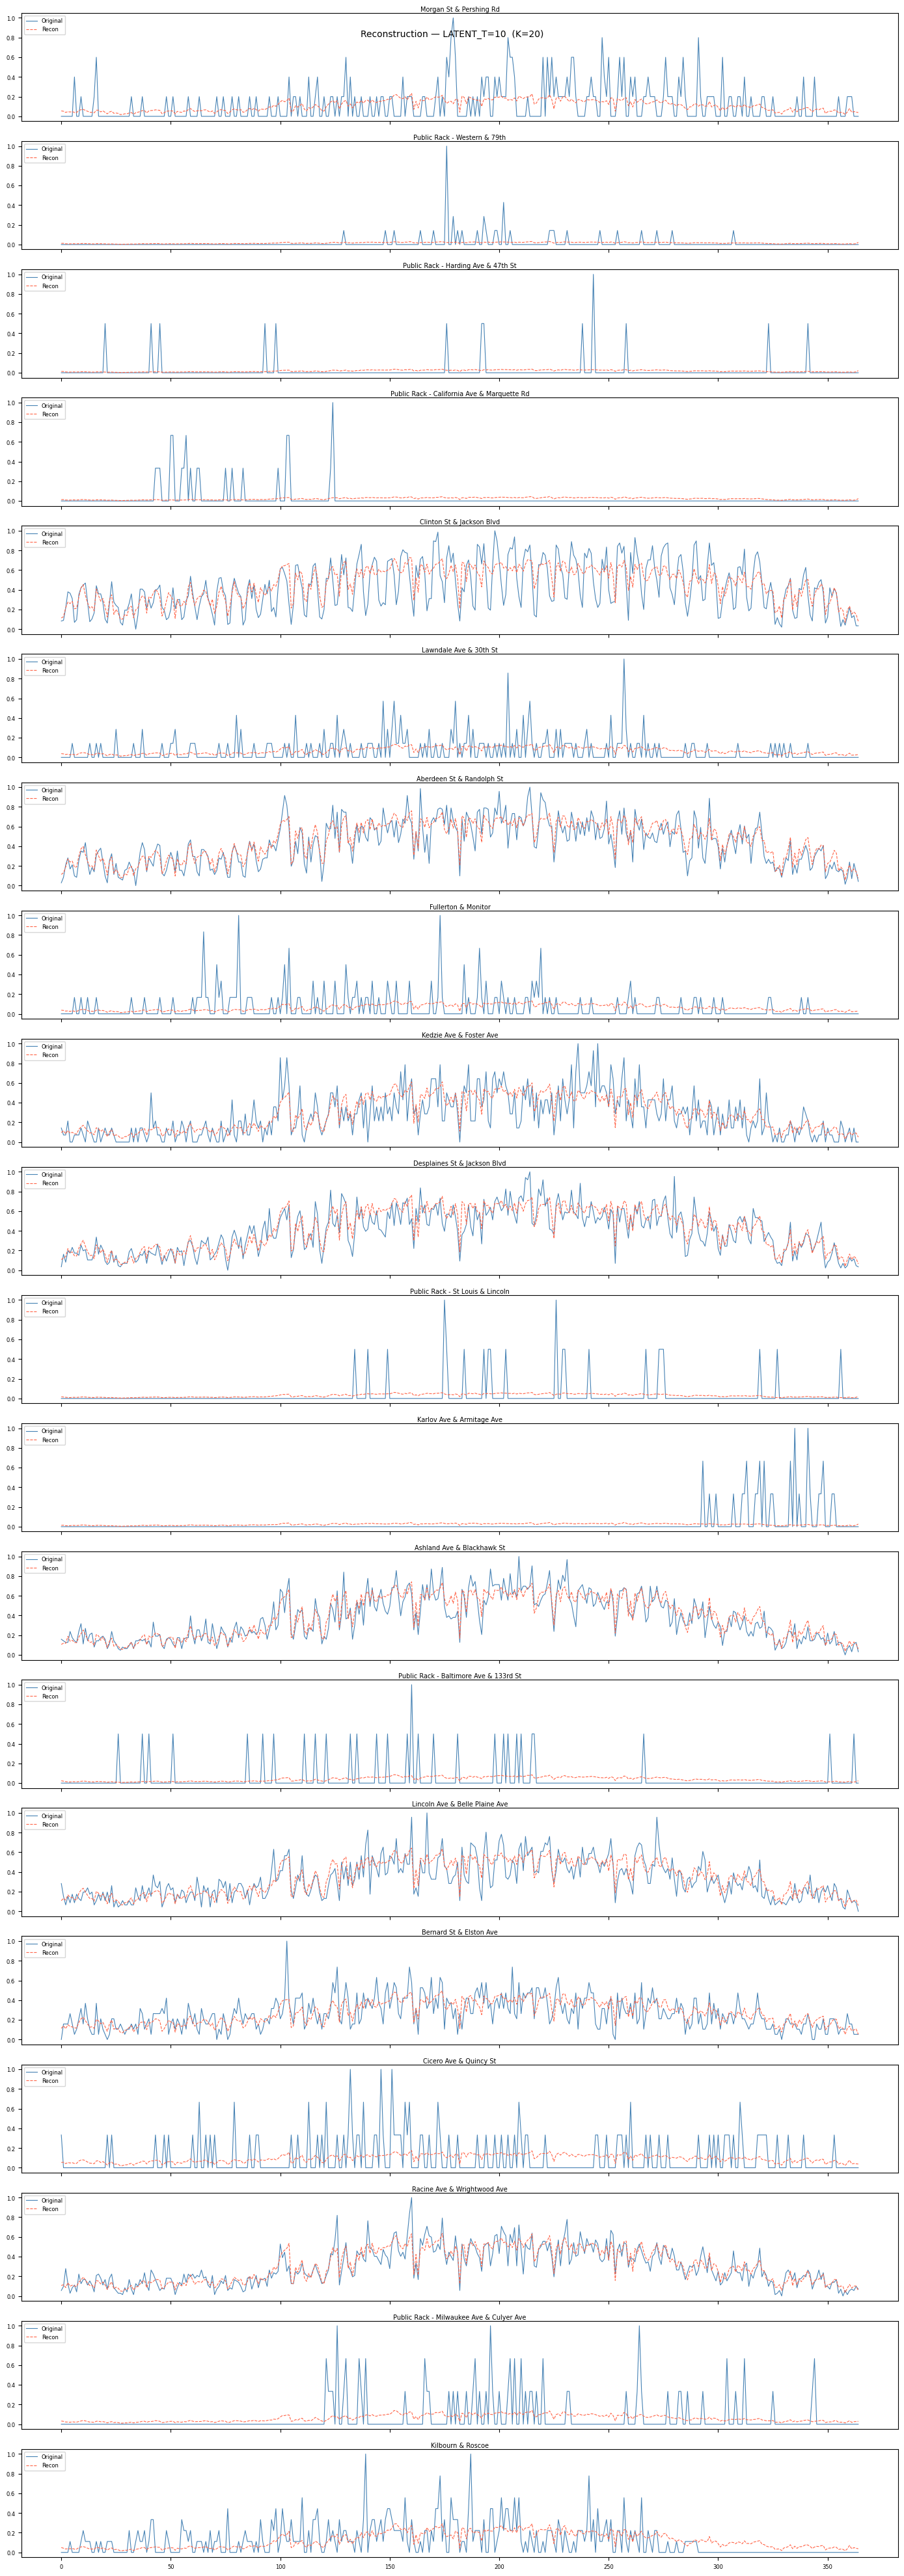

In [14]:
## 5. Reconstruction check
K_SAMPLES = 20  # number of stations to visualise

model.eval()
with torch.no_grad():
    X_recon = model(X_tensor.to(device)).cpu().numpy()

np.random.seed(0)
sample_idx = np.random.choice(n_stations, K_SAMPLES, replace=False)
fig, axes = plt.subplots(K_SAMPLES, 1, figsize=(14, 2 * K_SAMPLES), sharex=True)
if K_SAMPLES == 1:
    axes = [axes]
for ax, i in zip(axes, sample_idx):
    ax.plot(X[i, 0], color='steelblue', linewidth=0.8, label='Original')
    ax.plot(X_recon[i, 0], color='tomato', linestyle='--', linewidth=0.8, label='Recon')
    ax.set_title(pivot.index[i][:50], fontsize=7, pad=2)
    ax.tick_params(labelsize=6)
    ax.legend(fontsize=6, loc='upper left')
fig.suptitle(f'Reconstruction — LATENT_T={LATENT_T}  (K={K_SAMPLES})', fontsize=10)
plt.tight_layout(); plt.show()


Stations active on >=346 days: 418 / 1301
Latent: (418, 10)  →  t-SNE: (418, 2)


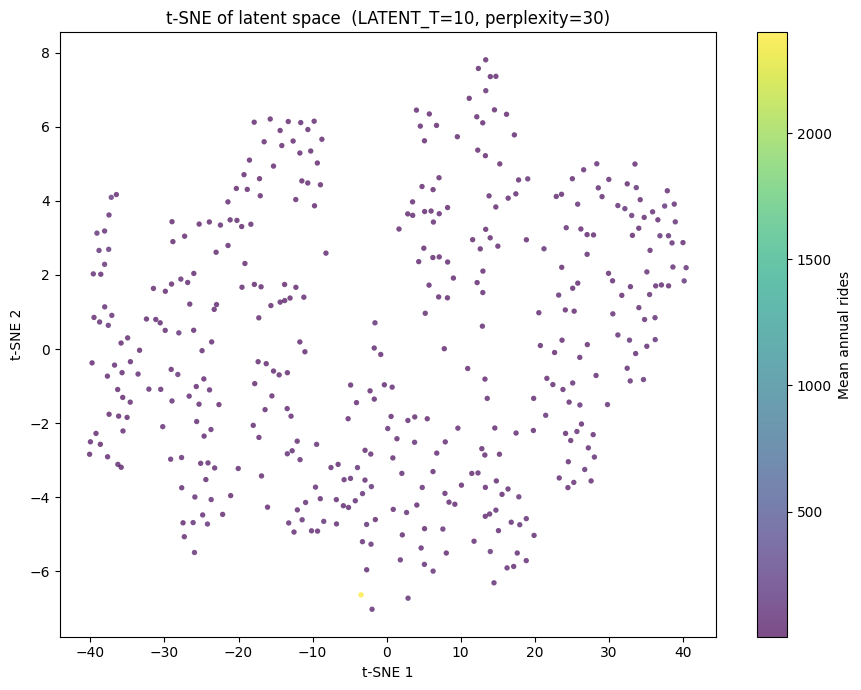

In [15]:
## 6. t-SNE of latent space
from sklearn.manifold import TSNE

TSNE_PERPLEXITY = 30   # playable: try 10, 30, 50
TSNE_SEED       = 42

# Same 95%-active filter as notebook 05
min_active = int(0.95 * pivot.shape[1])
active_idx = np.where((pivot > 0).sum(axis=1) >= min_active)[0]
print(f'Stations active on >={min_active} days: {len(active_idx)} / {len(pivot)}')

model.eval()
with torch.no_grad():
    Z_all = model.encode(X_tensor.to(device)).cpu().numpy()  # (n_stations, LATENT_T)
Z = Z_all[active_idx]                                         # filtered

z_2d = TSNE(n_components=2, perplexity=TSNE_PERPLEXITY,
            random_state=TSNE_SEED, init='pca').fit_transform(Z)
print(f'Latent: {Z.shape}  →  t-SNE: {z_2d.shape}')

mean_rides = pivot.mean(axis=1).values[active_idx]  # filtered

fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(z_2d[:, 0], z_2d[:, 1],
                c=mean_rides, cmap='viridis', s=15, alpha=0.7, linewidths=0)
plt.colorbar(sc, ax=ax, label='Mean annual rides')
ax.set_title(f't-SNE of latent space  (LATENT_T={LATENT_T}, perplexity={TSNE_PERPLEXITY})')
ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
plt.tight_layout(); plt.show()


Eigengap suggests k = 9


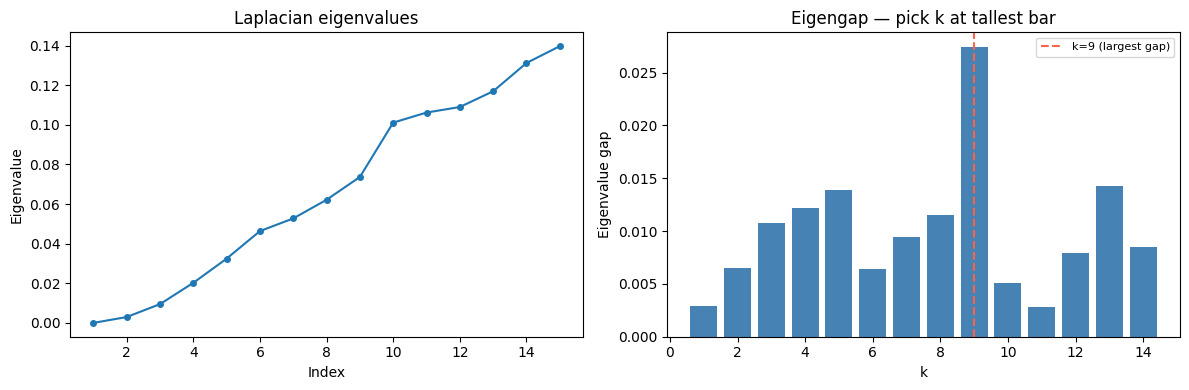

Cluster sizes: {np.int32(0): np.int64(56), np.int32(1): np.int64(58), np.int32(2): np.int64(78), np.int32(3): np.int64(37), np.int32(4): np.int64(40), np.int32(5): np.int64(39), np.int32(6): np.int64(31), np.int32(7): np.int64(34), np.int32(8): np.int64(45)}


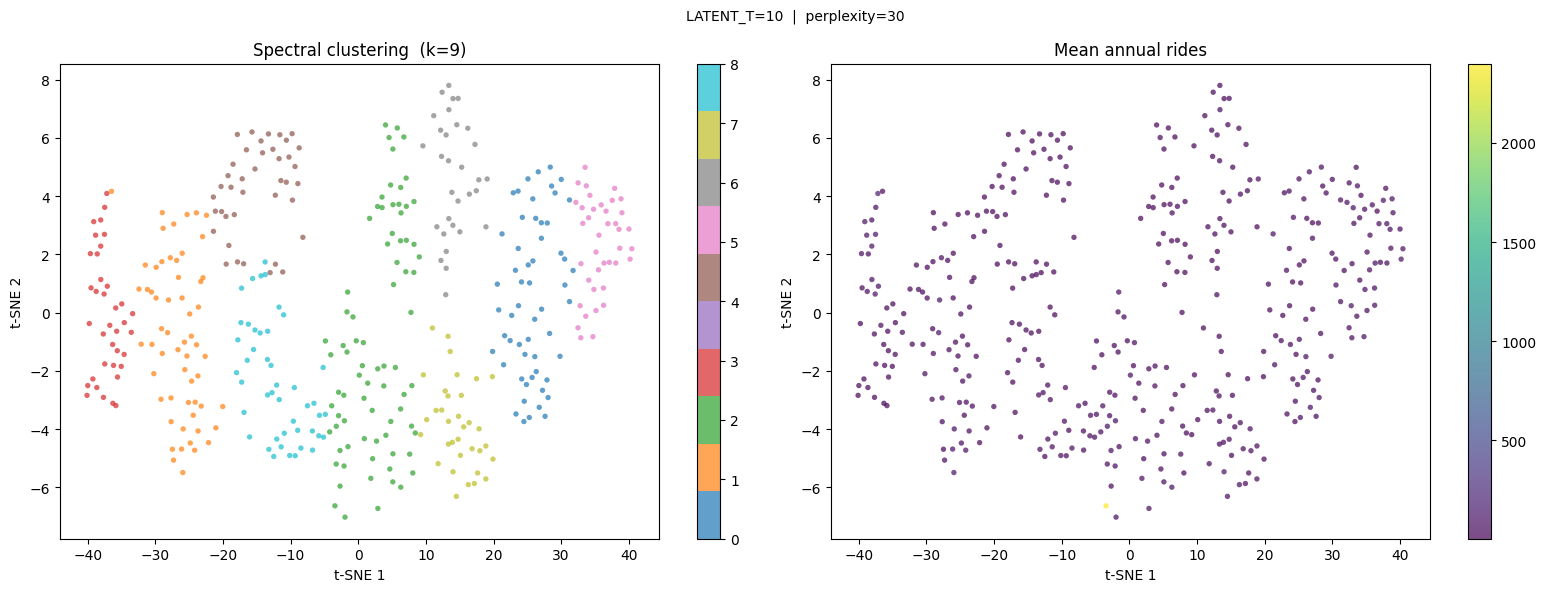

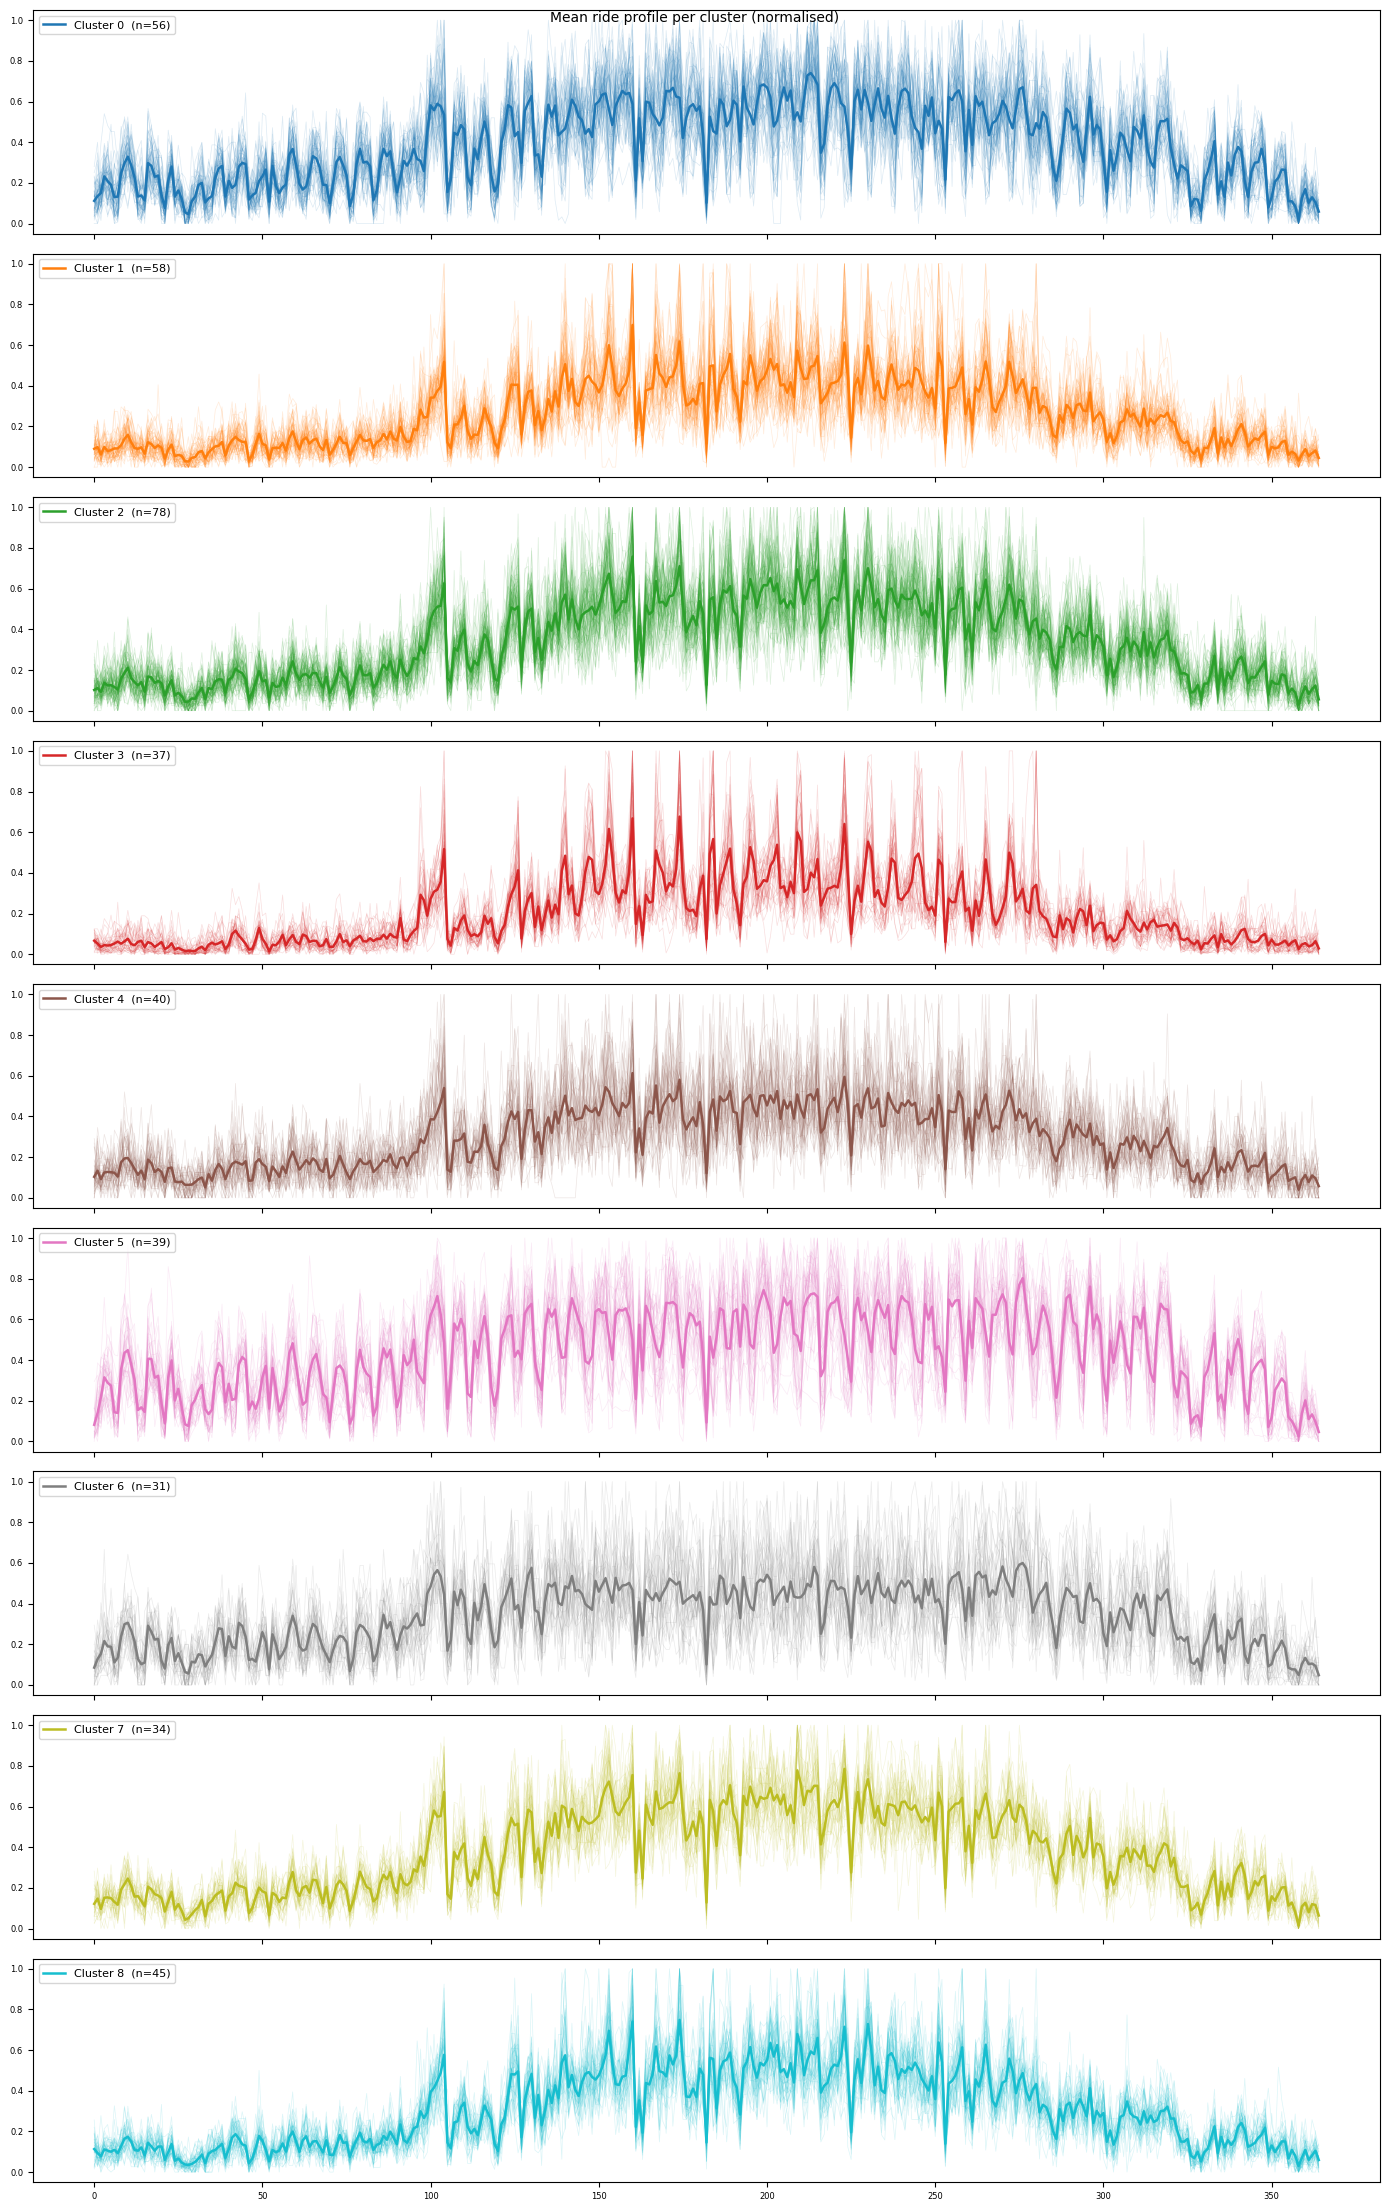

In [16]:
## 7. Spectral clustering on latent space
from sklearn.cluster import SpectralClustering
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import laplacian
from scipy.sparse.linalg import eigsh

# ── Eigengap heuristic: auto-pick k ────────────────────────
# Build the same affinity graph sklearn would use internally
N_NEIGHBORS = 10
A = kneighbors_graph(Z, n_neighbors=N_NEIGHBORS, mode='connectivity',
                     include_self=False)
A = (A + A.T)  # symmetrise
L = laplacian(A, normed=True)
# Smallest K_MAX eigenvalues (0 = trivial)
K_MAX = 15
eigenvalues = eigsh(L, k=K_MAX, which='SM', return_eigenvectors=False)
eigenvalues = np.sort(np.abs(eigenvalues))
gaps = np.diff(eigenvalues)
k_auto = int(np.argmax(gaps) + 1)   # +1 because diff shifts index by 1
print(f'Eigengap suggests k = {k_auto}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, K_MAX + 1), eigenvalues, marker='o', markersize=4)
axes[0].set_xlabel('Index'); axes[0].set_ylabel('Eigenvalue')
axes[0].set_title('Laplacian eigenvalues')
axes[1].bar(range(1, K_MAX), gaps, color='steelblue')
axes[1].axvline(k_auto, color='tomato', linestyle='--', label=f'k={k_auto} (largest gap)')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Eigenvalue gap')
axes[1].set_title('Eigengap — pick k at tallest bar')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# ── Fit with suggested k (override if you prefer) ──────────
N_CLUSTERS = k_auto   # change to a fixed int to override
labels = SpectralClustering(
    n_clusters=N_CLUSTERS, affinity='nearest_neighbors',
    n_neighbors=N_NEIGHBORS, random_state=42, n_jobs=-1,
).fit_predict(Z)
print(f'Cluster sizes: {dict(zip(*np.unique(labels, return_counts=True)))}')

# ── t-SNE coloured by cluster ──────────────────────────────
cmap = plt.get_cmap('tab10', N_CLUSTERS)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (c, title) in zip(axes, [
    (labels,     f'Spectral clustering  (k={N_CLUSTERS})'),
    (mean_rides, 'Mean annual rides'),
]):
    sc = ax.scatter(z_2d[:, 0], z_2d[:, 1], c=c,
                    cmap='tab10' if c is labels else 'viridis',
                    s=15, alpha=0.7, linewidths=0)
    plt.colorbar(sc, ax=ax)
    ax.set_title(title); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
plt.suptitle(f'LATENT_T={LATENT_T}  |  perplexity={TSNE_PERPLEXITY}', fontsize=10)
plt.tight_layout(); plt.show()

# ── Mean profile per cluster ───────────────────────────────
X_active = X[active_idx]
fig, axes = plt.subplots(N_CLUSTERS, 1, figsize=(14, 2.5 * N_CLUSTERS), sharex=True)
if N_CLUSTERS == 1:
    axes = [axes]
for k, ax in enumerate(axes):
    mask = labels == k
    profiles = X_active[mask, 0, :]
    ax.plot(profiles.T, color=cmap(k), alpha=0.15, linewidth=0.5)
    ax.plot(profiles.mean(axis=0), color=cmap(k), linewidth=1.8, label=f'Cluster {k}  (n={mask.sum()})')
    ax.legend(fontsize=8, loc='upper left')
    ax.tick_params(labelsize=6)
fig.suptitle('Mean ride profile per cluster (normalised)', fontsize=10)
plt.tight_layout(); plt.show()


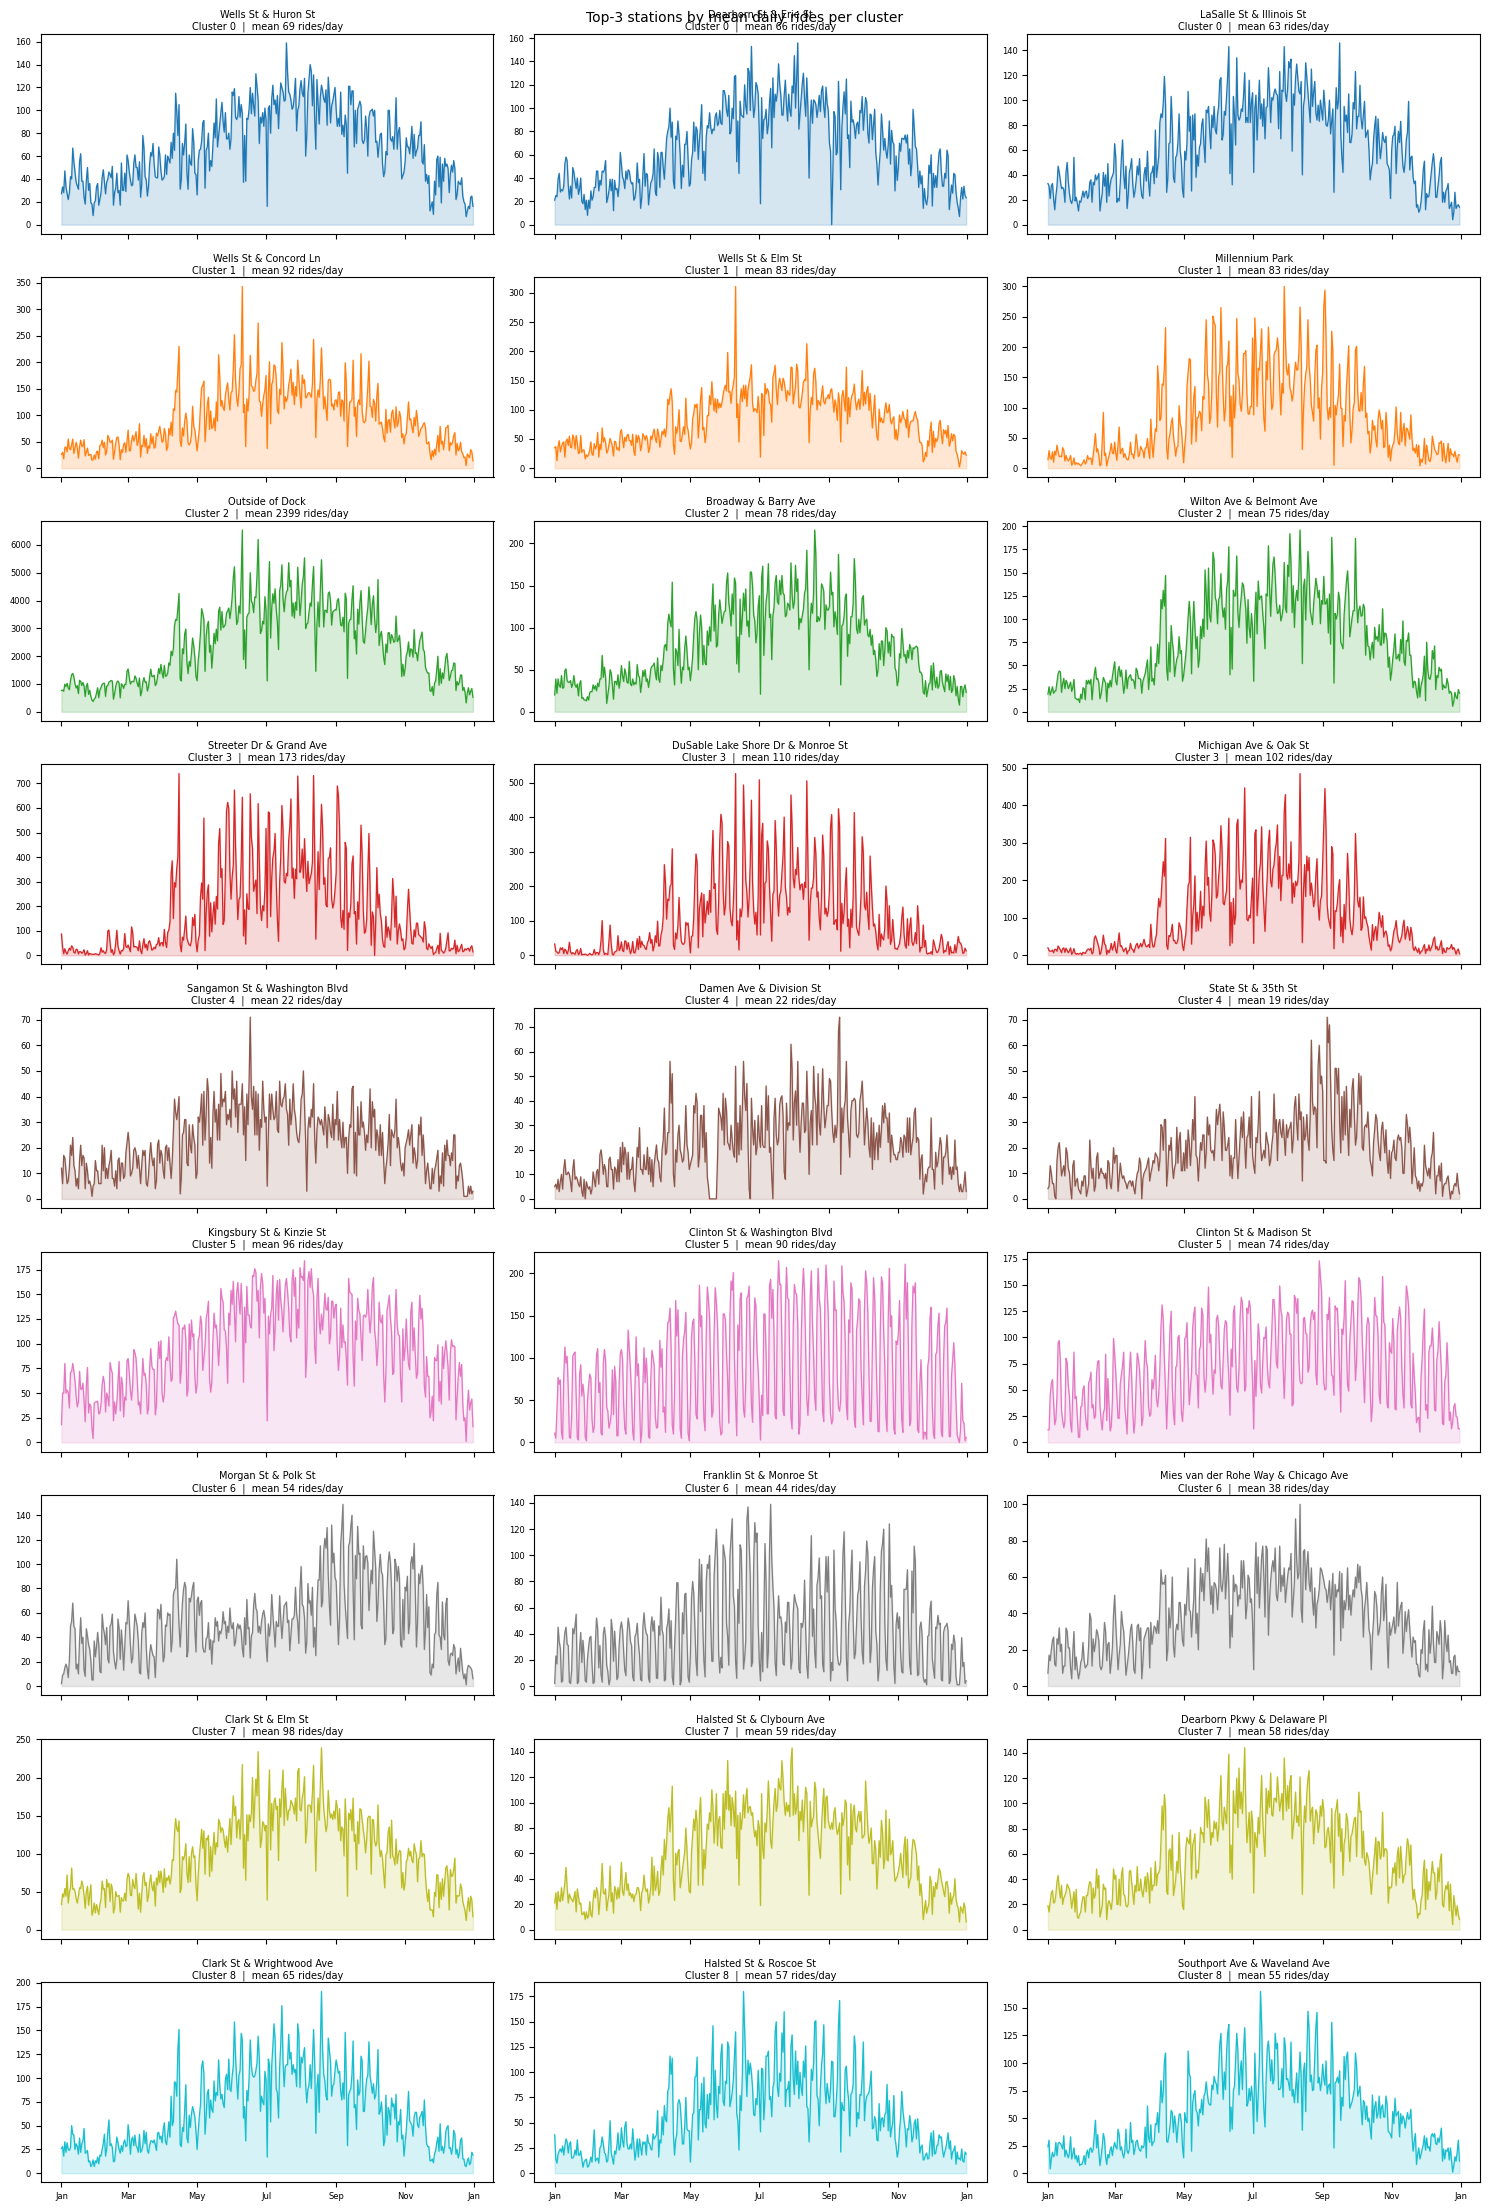

In [17]:
## 8. Top-3 stations by ride count per cluster
TOP_N = 3   # playable

mean_rides_series = pivot.mean(axis=1).iloc[active_idx]
cluster_ids = sorted(np.unique(labels))

fig, axes = plt.subplots(
    len(cluster_ids), TOP_N,
    figsize=(5 * TOP_N, 2.5 * len(cluster_ids)),
    sharex=True, sharey=False,
)
if len(cluster_ids) == 1:
    axes = [axes]

dates_idx = pivot.columns
cmap = plt.get_cmap('tab10', len(cluster_ids))

for row, k in enumerate(cluster_ids):
    local_mask  = np.where(labels == k)[0]
    sorted_local = local_mask[np.argsort(mean_rides_series.values[local_mask])[::-1][:TOP_N]]
    global_idx  = active_idx[sorted_local]
    color = cmap(row)

    for col, stn_idx in enumerate(global_idx):
        ax  = axes[row][col]
        raw = pivot.iloc[stn_idx].values
        ax.plot(dates_idx, raw, color=color, linewidth=0.9)
        ax.fill_between(dates_idx, raw, alpha=0.18, color=color)
        ax.set_title(
            f'{pivot.index[stn_idx][:35]}\n'
            f'Cluster {k}  |  mean {pivot.mean(axis=1).iloc[stn_idx]:.0f} rides/day',
            fontsize=7, pad=3,
        )
        ax.tick_params(labelsize=6)
        ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b'))

fig.suptitle(f'Top-{TOP_N} stations by mean daily rides per cluster', fontsize=10)
plt.tight_layout(); plt.show()


In [18]:
## 9. Cluster map (Folium)
import folium

# --- fetch station coords from raw trip data ---
raw_frames = []
for month in [3, 6, 9]:
    raw = s3.read_raw(2023, month)
    raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())
coords_df = pd.concat(raw_frames, ignore_index=True)
station_coords = (
    coords_df.groupby('start_station_name')[['start_lat', 'start_lng']]
    .mean().reset_index()
)
print(f'Stations with coords: {len(station_coords)}')

# --- build cluster assignment df (active stations only) ---
cluster_df = pd.DataFrame({
    'start_station_name': pivot.index[active_idx],
    'cluster': labels,
})
map_df = cluster_df.merge(station_coords, on='start_station_name', how='left')
map_df = map_df.dropna(subset=['start_lat', 'start_lng'])
print(f'Stations on map: {len(map_df)}')

# --- colour palette ---
PALETTE = ['#FF0000','#0070FF','#00CC00','#FF00FF','#FF8C00',
           '#00CED1','#8B008B','#2E8B57','#FF6347','#4169E1']
cluster_ids = sorted(map_df['cluster'].unique())
color_map   = {k: PALETTE[i % len(PALETTE)] for i, k in enumerate(cluster_ids)}

# --- build map ---
m = folium.Map(location=[41.8781, -87.6298], zoom_start=11, tiles='OpenStreetMap')

station_groups = {k: folium.FeatureGroup(name=f'Cluster {k} stations') for k in cluster_ids}
for _, row in map_df.iterrows():
    k = row['cluster']
    folium.CircleMarker(
        location=[row['start_lat'], row['start_lng']],
        radius=4, color=color_map[k],
        fill=True, fill_color=color_map[k], fill_opacity=0.75, weight=1,
        popup=folium.Popup(f"<b>{row['start_station_name']}</b><br>Cluster {k}", max_width=250),
        tooltip=row['start_station_name'],
    ).add_to(station_groups[k])
for g in station_groups.values():
    g.add_to(m)

density_groups = {k: folium.FeatureGroup(name=f'Cluster {k} density', show=False) for k in cluster_ids}
for _, row in map_df.iterrows():
    k = row['cluster']
    folium.CircleMarker(
        location=[row['start_lat'], row['start_lng']],
        radius=15, color=color_map[k],
        fill=True, fill_color=color_map[k], fill_opacity=0.12, weight=1, opacity=0.3,
    ).add_to(density_groups[k])
for g in density_groups.values():
    g.add_to(m)

folium.LayerControl(collapsed=True).add_to(m)

legend_items = ''.join([
    f'<div><svg height="12" width="12"><circle cx="6" cy="6" r="5" fill="{color_map[k]}"/></svg>'
    f'<span style="padding-left:8px;">Cluster {k} ({(map_df["cluster"]==k).sum()} stations)</span></div><br>'
    for k in cluster_ids
])
legend_html = (
    '<div style="position:fixed;bottom:50px;right:50px;width:200px;'
    'border:2px solid grey;z-index:9999;font-size:10px;'
    'background-color:white;padding:8px;border-radius:5px;'
    'box-shadow:0 0 15px rgba(0,0,0,0.2);">'
    '<div style="text-align:center;"><b>Divvy Station Clusters</b></div>'
    '<hr style="margin:8px 0;">'
    + legend_items +
    '</div>'
)
m.get_root().html.add_child(folium.Element(legend_html))

m.save('cluster_map_exp08.html')
print('Saved to cluster_map_exp08.html')
m


Stations with coords: 1430
Stations on map: 417
Saved to cluster_map_exp08.html
